# PRISMA: from L1 to the hGRS L2A product

This notebook opens a PRISMA L2A product processed with hGRS together with the PRISMA files given as
input to the processor, and compares them on the same grid:

* the **L1** top-of-atmosphere (TOA) radiance (`PRS_L1_STD_OFFL_*.he5`), converted into TOA reflectance
  $R_{TOA}$ from 400 to 2500 nm;
* the **L2C** surface reflectance of the Italian Space Agency (ASI) (`PRS_L2C_STD_*.he5`), from which
  hGRS takes the viewing angles;
* the **hGRS L2A** remote-sensing reflectance $R_{rs}$ and sunglint amplitude.

**Workflow**

1. open the hGRS L2A product with grstbx;
2. read the PRISMA L1 and L2C files and interpolate them onto the grid of the L2A product;
3. compare the true-colour composites before and after the atmospheric and sunglint correction;
4. map the parameters retrieved by hGRS on the mega-pixels (aerosol, water vapor, sunglint);
5. map the viewing geometry;
6. plot the spectra of points of interest, from TOA to $R_{rs}$;
7. plot $R_{rs}$ along a spectral transect;
8. compare $R_{rs}$ with the ASI L2C reflectance;
9. explore the image with the interactive viewer of [grstbx](https://github.com/Tristanovsk/grstbx),
   to be run in Jupyter.

**Data**: the PRISMA image of 2026-02-06 over three islands of the South Atlantic coast of Brazil
(39.3-38.95° W, 18.15-17.8° S), with strong sunglint. The files are not distributed with grstbx: set
the paths of the *Input files* cell to run the notebook on your own data.

## Setup

Imports: the PRISMA files are read with the `hgrs` package and interpolated with
[xESMF](https://xesmf.readthedocs.io); grstbx opens the L2A product and draws the maps.

In [1]:
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import pyproj
import xesmf as xe
import rioxarray  # noqa: F401, enables the .rio accessor

import hgrs
from grstbx import utils
from grstbx.driver import open_hgrs_l2a

# xESMF warns that the PRISMA arrays are not contiguous in memory: no effect on the results
warnings.filterwarnings('ignore', message='Input array is not')
warnings.filterwarnings('ignore', category=FutureWarning)

### Input files

The L2A product and the two PRISMA files it was processed from (same acquisition time in the names).

In [2]:
l1_dir = '/data/satellite/prisma/L1/thais'
l2a_dir = '/data/satellite/prisma/L2A/thais'
acquisition = '20260206130152_20260206130157_0001'

l1_file = f'{l1_dir}/PRS_L1_STD_OFFL_{acquisition}.he5'
l2c_file = f'{l1_dir}/PRS_L2C_STD_{acquisition}.he5'
l2a_file = f'{l2a_dir}/PRS_L2A_hgrs_{acquisition}_V1.1.2.nc'

## 1. The hGRS L2A product

hGRS projects the PRISMA image (in sensor geometry) onto a regular longitude-latitude grid of
1200 x 1200 pixels (EPSG 4326) covering the image. The product holds:

* on the full-resolution grid `x`, `y` (longitude, latitude): $R_{rs}$ from 400 to 1100 nm (`wl`) and the
  sunglint amplitude `brdfg_full`; the bands of strong water vapor absorption are removed (NaN);
* on the coarse grid of the mega-pixels `xc`, `yc`: aerosol optical thickness at 550 nm (`aot_ref`, and
  `aot_ref_smoothed`), water vapor (`tcwv`), sunglint (`brdfg`), their uncertainties and the proportion
  of water pixels (`water_pix_prop`).

`open_hgrs_l2a` of grstbx opens the file lazily and splits it as a GRS product: the full-resolution
variables, and the coarse-grid and scalar variables as the *ancillary* dataset.

In [3]:
l2a, ancillary = open_hgrs_l2a(l2a_file)
print(f"hGRS {l2a.attrs['hgrs_version']}, aerosol model {l2a.attrs['aerosol_model']}, "
      f"date {l2a.attrs['acquisition_date']}")
l2a

hGRS 1.1.2, aerosol model ARCT_rh70, date 2026-02-06T13:01:52.974999


<xarray.Dataset> Size: 852MB
Dimensions:      (wl: 73, y: 1200, x: 1200)
Coordinates:
  * wl           (wl) float32 292B 407.0 415.8 423.8 ... 1.089e+03 1.099e+03
  * y            (y) float32 5kB -18.14 -18.14 -18.14 ... -17.82 -17.82 -17.82
  * x            (x) float32 5kB -39.3 -39.3 -39.3 ... -38.95 -38.95 -38.95
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B ...
Data variables:
    Rrs          (wl, y, x) float64 841MB dask.array<chunksize=(25, 400, 400), meta=np.ndarray>
    brdfg_full   (y, x) float64 12MB dask.array<chunksize=(1200, 1200), meta=np.ndarray>
Attributes: (12/39)
    regrid_method:                   bilinear
    description:                     PRISMA L2A-hGRS cube data
    L1C_product_name:                PRS_L1_STD_OFFL_20260206130152_202602061...
    acquisition_date:                2026-02-06T13:01:52.974999
    sza:                             26.093828
    saa:                             88.64304
    ...                              ...
    to3c:                            0.005715703591704369
    tno2c:                           1.6688413779775146e-06
    tch4c:                           0.010239937342703342
    psl:                             1013
    coef_abs_scat:                   0.35
    altitude:                        0

## 2. The PRISMA L1 and L2C files on the L2A grid

`hgrs.Driver` reads the PRISMA files as hGRS does, in sensor geometry:

* `read_l1c_prisma` converts the L1 radiance into TOA reflectance
  $R_{TOA} = \pi L_{TOA} / (F_0 \cos\theta_s)$ with the TSIS-1 solar irradiance;
* `read_l2c_prisma` reads the ASI L2C surface reflectance $\rho$ and the solar and viewing angles.

The images are then interpolated (bilinear, with [xESMF](https://xesmf.readthedocs.io)) onto the grid of
the L2A product, from the longitude and latitude of each pixel: hGRS builds its grid in the same way, so the
L1, L2C and L2A pixels match. Each file has its own wavelengths; they are renamed `wl_toa` and `wl_l2c` to
be kept in the same dataset as $R_{rs}$. This step takes a few minutes and about 3 GB of memory.

In [4]:
def to_l2a_grid(image, l2a):
    """Bilinear interpolation of an image in sensor geometry (2D lon, lat) onto the grid of the L2A product."""
    grid = xr.Dataset(coords={'lon': l2a.x.values, 'lat': l2a.y.values})
    regridder = xe.Regridder(image, grid, 'bilinear', unmapped_to_nan=True)
    return regridder(image).rename(lon='x', lat='y').assign_coords(x=l2a.x, y=l2a.y)


prisma = hgrs.Driver('prisma')

l1 = prisma.read_l1c_prisma(l1_file, reflectance_unit=True, drop_vars=True)
l1 = l1[['Rtoa']].astype('float32').assign_coords(lon=l1.lon, lat=l1.lat)
l1 = to_l2a_grid(l1, l2a).rename(wl='wl_toa')

l2c = prisma.read_l2c_prisma(l2c_file)
l2c = l2c[['rho', 'sza', 'vza', 'raa']].astype('float32').assign_coords(lon=l2c.lon, lat=l2c.lat)
l2c = to_l2a_grid(l2c, l2a).rename(wl='wl_l2c', rho='rho_l2c')

scene = xr.merge([l2a[['Rrs', 'brdfg_full']], l1, l2c.drop_vars('time', errors='ignore')],
                 compat='override').rio.write_crs(4326)
scene

<xarray.Dataset> Size: 4GB
Dimensions:      (wl: 73, y: 1200, x: 1200, wl_toa: 232, wl_l2c: 234)
Coordinates:
  * wl           (wl) float32 292B 407.0 415.8 423.8 ... 1.089e+03 1.099e+03
  * y            (y) float32 5kB -18.14 -18.14 -18.14 ... -17.82 -17.82 -17.82
  * x            (x) float32 5kB -39.3 -39.3 -39.3 ... -38.95 -38.95 -38.95
  * wl_toa       (wl_toa) float32 928B 407.0 415.8 423.8 ... 2.49e+03 2.497e+03
  * wl_l2c       (wl_l2c) float32 936B 407.0 415.8 423.8 ... 2.49e+03 2.497e+03
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0
Data variables:
    Rrs          (wl, y, x) float64 841MB dask.array<chunksize=(25, 400, 400), meta=np.ndarray>
    brdfg_full   (y, x) float64 12MB dask.array<chunksize=(1200, 1200), meta=np.ndarray>
    Rtoa         (wl_toa, y, x) float32 1GB nan nan nan nan ... nan nan nan nan
    rho_l2c      (wl_l2c, y, x) float32 1GB nan nan nan nan ... nan nan nan nan
    sza          (y, x) float32 6MB nan nan nan nan nan ... nan nan nan nan nan
    vza          (y, x) float32 6MB nan nan nan nan nan ... nan nan nan nan nan
    raa          (y, x) float32 6MB nan nan nan nan nan ... nan nan nan nan nan
Attributes: (12/39)
    regrid_method:                   bilinear
    description:                     PRISMA L2A-hGRS cube data
    L1C_product_name:                PRS_L1_STD_OFFL_20260206130152_202602061...
    acquisition_date:                2026-02-06T13:01:52.974999
    sza:                             26.093828
    saa:                             88.64304
    ...                              ...
    to3c:                            0.005715703591704369
    tno2c:                           1.6688413779775146e-06
    tch4c:                           0.010239937342703342
    psl:                             1013
    coef_abs_scat:                   0.35
    altitude:                        0

## 3. True-colour composites and sunglint

From left to right: the L1 TOA reflectance, the hGRS $R_{rs}$ and the sunglint amplitude removed by hGRS.
`utils.plot_rgb` of grstbx draws each composite on map axes in the projection of the image (here
longitude-latitude); a gamma of 0.5 enhances the dark water pixels.

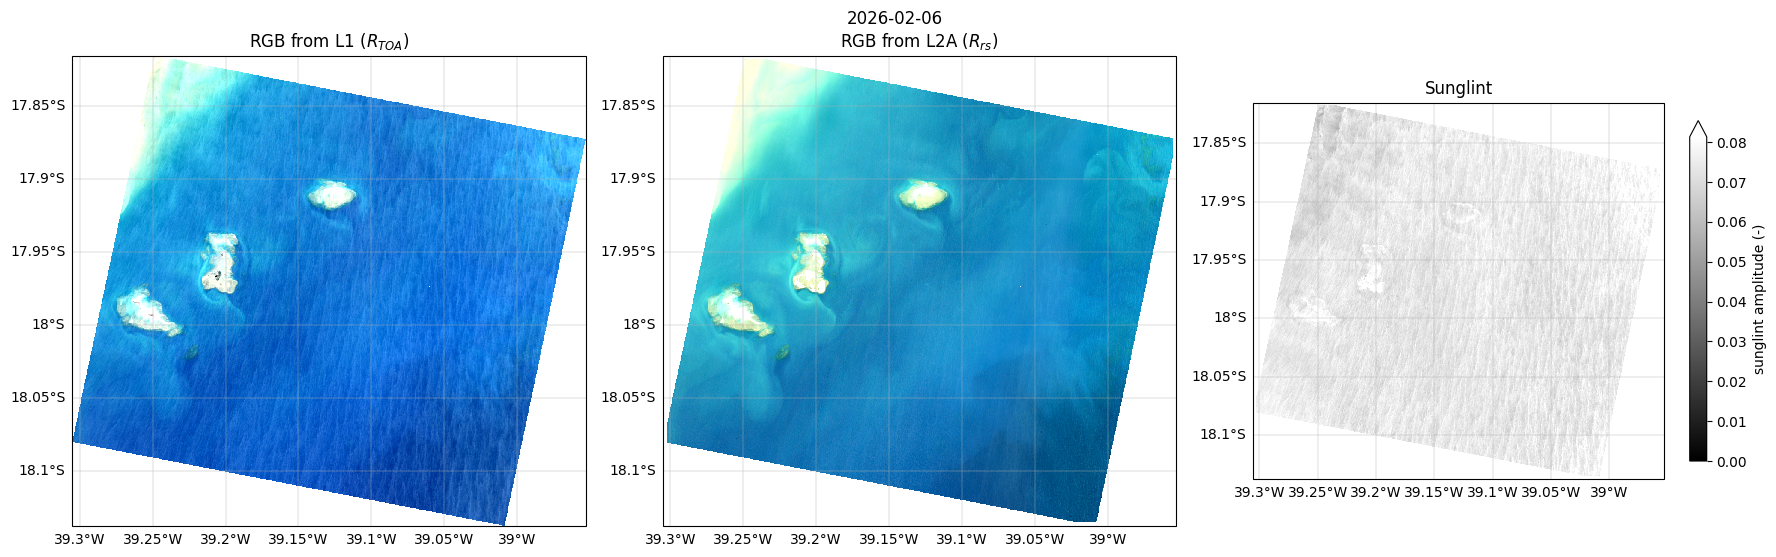

In [5]:
date = str(scene.time.dt.date.values)
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5),  width_ratios=[1, 1, 1.25], subplot_kw={'projection': ccrs.PlateCarree()})
utils.plot_rgb(scene.Rtoa.rename(wl_toa='wl').transpose('wl', 'y', 'x'), ax=axs[0])
axs[0].set_title('RGB from L1 ($R_{TOA}$)')
utils.plot_rgb(scene, ax=axs[1])
axs[1].set_title('RGB from L2A ($R_{rs}$)')
scene.brdfg_full.plot.imshow(ax=axs[2], cmap='gray', vmin=0, robust=True,
                             cbar_kwargs={'shrink': 0.7, 'label': 'sunglint amplitude (-)'})
axs[2].set_title('Sunglint')
for ax in axs:
    ax.gridlines(draw_labels=['bottom', 'left'], lw=0.3, x_inline=False, y_inline=False)
fig.suptitle(date)
plt.tight_layout()

## 4. Parameters retrieved on the mega-pixels

Aerosol optical thickness at 550 nm, water vapor and sunglint are retrieved on mega-pixels of
20 x 20 pixels, from their water pixels (proportion on the right); the grey cells have too few water
pixels.

 aot_ref_smoothed: mean 0.122, std 0.056
             tcwv: mean 23.202, std 0.569
            brdfg: mean 0.088, std 0.004


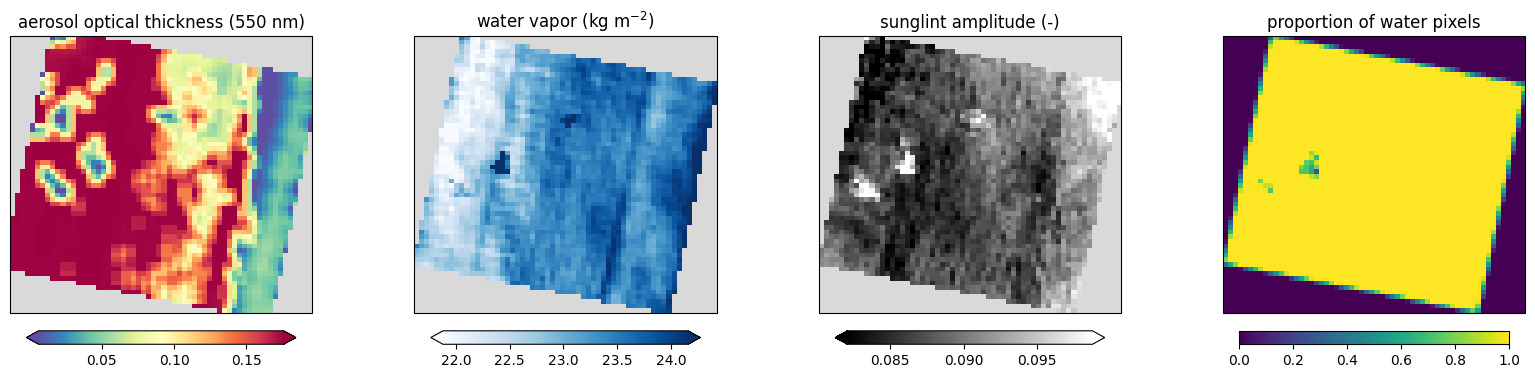

In [6]:
params = {'aot_ref_smoothed': ('aerosol optical thickness (550 nm)', 'Spectral_r'),
          'tcwv': ('water vapor (kg m$^{-2}$)', 'Blues'),
          'brdfg': ('sunglint amplitude (-)', 'gray'),
          'water_pix_prop': ('proportion of water pixels', 'viridis')}

fig, axs = plt.subplots(1, 4, figsize=(20, 4.5), subplot_kw={'projection': ccrs.PlateCarree()})
for ax, (name, (label, cmap)) in zip(axs, params.items()):
    ax.set_facecolor('0.85')
    ancillary[name].plot.imshow(ax=ax, x='xc', y='yc', cmap=cmap, robust=True,
                          cbar_kwargs={'shrink': 0.8, 'label': '', 'orientation': 'horizontal', 'pad': 0.05})
    ax.set_title(label)
for name in ['aot_ref_smoothed', 'tcwv', 'brdfg']:
    print(f'{name:>17}: mean {float(ancillary[name].mean()):.3f}, std {float(ancillary[name].std()):.3f}')

## 5. Viewing geometry

The sunglint depends on the angle between the viewing direction and the direction of specular reflection
of the sun: hGRS takes the solar zenith angle $\theta_s$, the viewing zenith angle $\theta_v$ and the
relative azimuth from the L2C file.

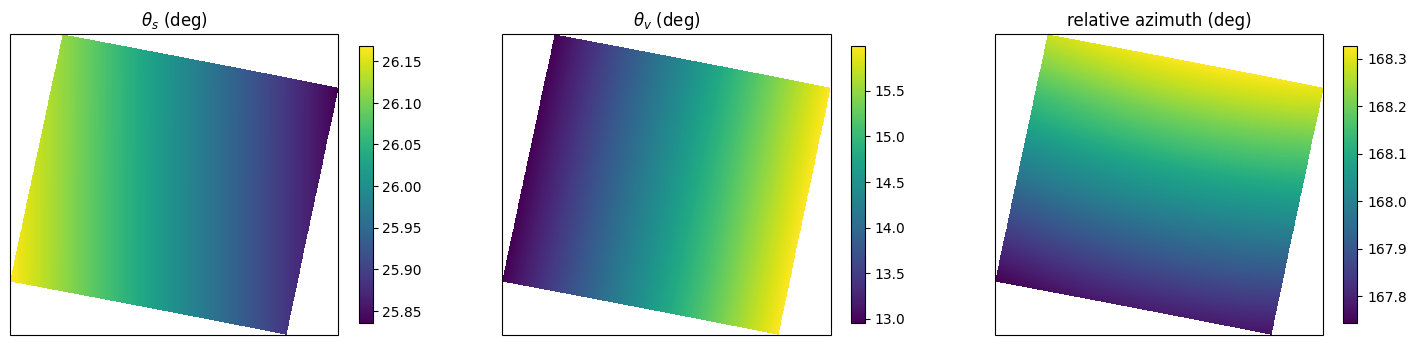

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5), subplot_kw={'projection': ccrs.PlateCarree()})
for ax, (name, label) in zip(axs, {'sza': r'$\theta_s$ (deg)', 'vza': r'$\theta_v$ (deg)',
                                    'raa': 'relative azimuth (deg)'}.items()):
    scene[name].plot.imshow(ax=ax, cmap='viridis', cbar_kwargs={'shrink': 0.8, 'label': ''})
    ax.set_title(label)

## 6. Spectra of points of interest

Four points: green water close to the western islands, the plume east of the central island, clear water
offshore, and a pixel on the central island. For each point, the upper panel gives the TOA reflectance
over the whole PRISMA range (the grey bands are the strong water vapor and oxygen absorption bands removed by
hGRS, the yellow band the SWIR window used for the sunglint); the lower panel gives the hGRS $R_{rs}$ and
the ASI L2C reflectance converted into $R_{rs}$ ($\rho / \pi$).

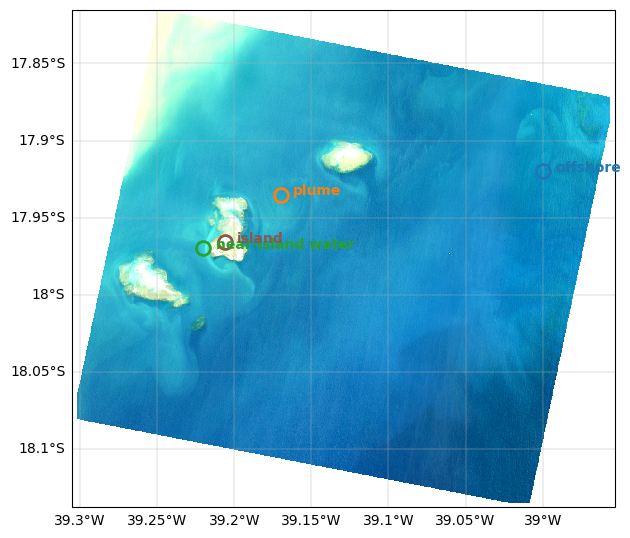

In [8]:
points = pd.DataFrame({'name': ['near-island water', 'plume', 'offshore', 'island'],
                       'lon': [-39.22, -39.17, -39.00, -39.206],
                       'lat': [-17.97, -17.935, -17.92, -17.966],
                       'color': ['tab:green', 'tab:orange', 'tab:blue', 'tab:brown']})

ax = utils.plot_rgb(scene, figsize=(7, 7))
ax.gridlines(draw_labels=['bottom', 'left'], lw=0.3, x_inline=False, y_inline=False)
for _, point in points.iterrows():
    ax.plot(point.lon, point.lat, 'o', mfc='none', mec=point.color, mew=2, ms=10, transform=ccrs.PlateCarree())
    ax.text(point.lon + 0.008, point.lat, point['name'], color=point.color, fontweight='bold',
            transform=ccrs.PlateCarree())

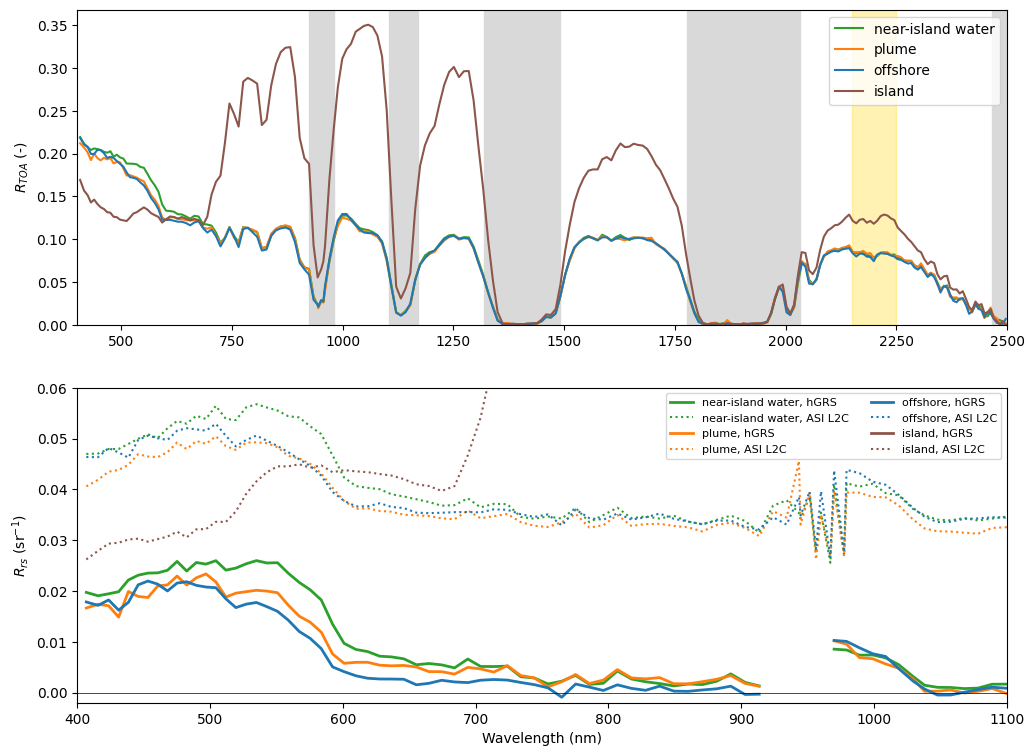

In [9]:
removed_bands = [(924, 980), (1105, 1170), (1320, 1490), (1778, 2033), (2465, 2550)]

fig, axs = plt.subplots(2, 1, figsize=(12, 9), sharex=False)
for _, point in points.iterrows():
    pixel = scene.sel(x=point.lon, y=point.lat, method='nearest')
    axs[0].plot(pixel.wl_toa, pixel.Rtoa, color=point.color, label=point['name'])
    axs[1].plot(pixel.wl, pixel.Rrs, color=point.color, lw=2, label=f"{point['name']}, hGRS")
    axs[1].plot(pixel.wl_l2c, pixel.rho_l2c / np.pi, color=point.color, ls=':', label=f"{point['name']}, ASI L2C")

for start, end in removed_bands:
    axs[0].axvspan(start, end, color='0.85', zorder=0)
axs[0].axvspan(2150, 2250, color='gold', alpha=0.3, zorder=0)
axs[0].set(ylabel='$R_{TOA}$ (-)', xlim=(400, 2500), ylim=(0, None))
axs[0].legend()
axs[1].axhline(0, color='k', lw=0.5)
axs[1].set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)', xlim=(400, 1100), ylim=(-0.002, 0.06))
axs[1].legend(ncol=2, fontsize=8);

The island pixel has no $R_{rs}$: hGRS masks the land pixels (NaN); its TOA spectrum shows the red edge of
the vegetation at 700 nm. Over water, the TOA reflectance remains high in the SWIR (about 0.08 at
2200 nm), where water absorbs all the light: this is the sunglint, which hGRS estimates in the SWIR window
and removes at all wavelengths. The ASI L2C reflectance, not corrected for the sunglint, is higher than
the hGRS $R_{rs}$ by a nearly constant offset.

## 7. Spectral transect

$R_{rs}$ along a line from the near-island water to the open ocean, as an image (wavelength x distance)
and at three wavelengths. The line is sampled at the resolution of the grid (nearest pixel); it starts on
the shallow bright waters of the western island and crosses the edge of the central island (gap at 6 km).

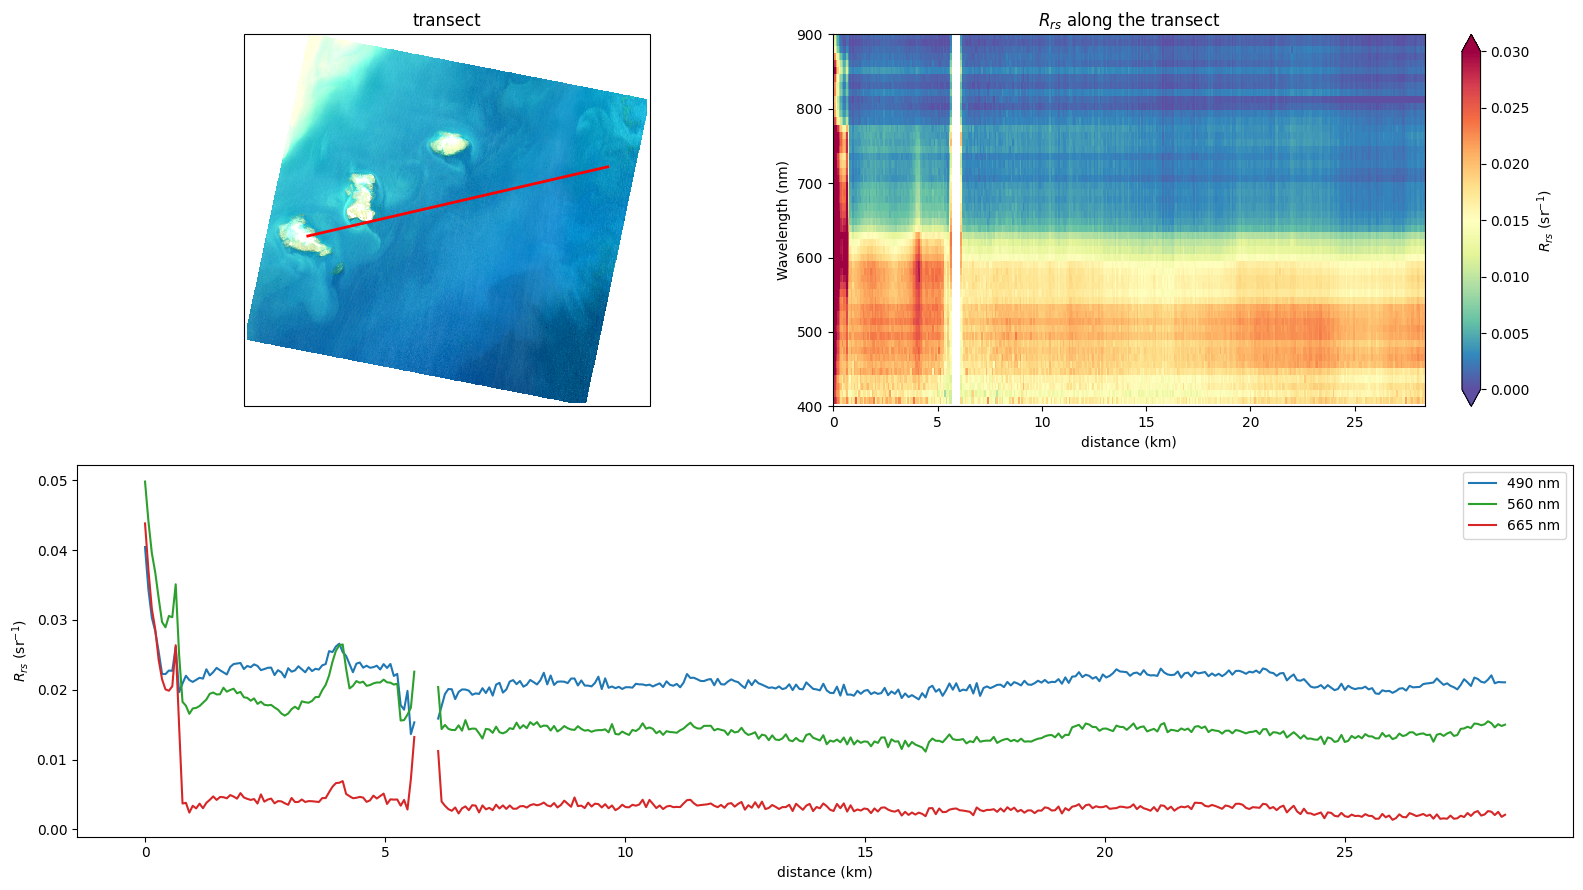

In [10]:
start, end = (-39.25, -17.99), (-38.99, -17.93)
geod = pyproj.Geod(ellps='WGS84')
npoints = 400
lons = xr.DataArray(np.linspace(start[0], end[0], npoints), dims='distance')
lats = xr.DataArray(np.linspace(start[1], end[1], npoints), dims='distance')
distance = np.linspace(0, geod.inv(*start, *end)[2] / 1000, npoints)

transect = scene.Rrs.sel(x=lons, y=lats, method='nearest').assign_coords(distance=distance)

fig = plt.figure(figsize=(16, 9))
ax_map = fig.add_subplot(2, 2, 1, projection=ccrs.PlateCarree())
utils.plot_rgb(scene, ax=ax_map)
ax_map.plot([start[0], end[0]], [start[1], end[1]], 'r-', lw=2, transform=ccrs.PlateCarree())
ax_map.set_title('transect')

ax = fig.add_subplot(2, 2, 2)
transect.plot.imshow(ax=ax, x='distance', y='wl', cmap='Spectral_r', vmin=0, vmax=0.03,
                     cbar_kwargs={'label': '$R_{rs}$ (sr$^{-1}$)'})
ax.set(xlabel='distance (km)', ylabel='Wavelength (nm)', ylim=(400, 900), title='$R_{rs}$ along the transect')

ax = fig.add_subplot(2, 1, 2)
for wl, color in zip([490, 560, 665], ['tab:blue', 'tab:green', 'tab:red']):
    transect.sel(wl=wl, method='nearest').plot(ax=ax, color=color, label=f'{wl} nm')
ax.set(xlabel='distance (km)', ylabel='$R_{rs}$ (sr$^{-1}$)', title='')
ax.legend()
plt.tight_layout()

## 8. hGRS and ASI L2C reflectances

Pixel by pixel comparison of the hGRS $R_{rs}$ and the ASI L2C $\rho / \pi$ over the water pixels
(one pixel out of four in each direction). The L2C values are higher by about 0.03 sr$^{-1}$ at all
wavelengths: the sunglint, not removed in the L2C product.

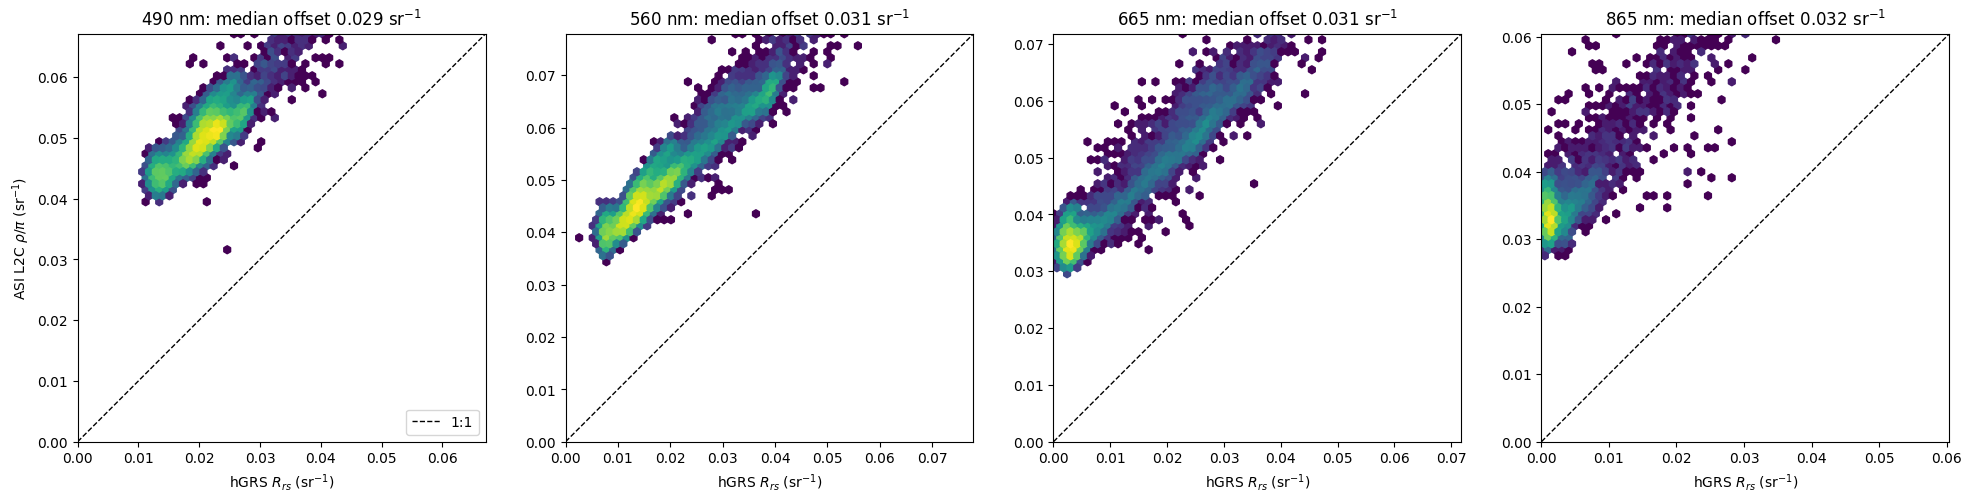

In [11]:
sample = scene.isel(x=slice(None, None, 4), y=slice(None, None, 4))
wavelengths = [490, 560, 665, 865]

fig, axs = plt.subplots(1, len(wavelengths), figsize=(20, 4.8))
for ax, wl in zip(axs, wavelengths):
    rrs = sample.Rrs.sel(wl=wl, method='nearest').values.ravel()
    l2c_rrs = (sample.rho_l2c.sel(wl_l2c=wl, method='nearest') / np.pi).values.ravel()
    valid = np.isfinite(rrs) & np.isfinite(l2c_rrs)
    rrs, l2c_rrs = rrs[valid], l2c_rrs[valid]
    vmax = np.quantile(l2c_rrs, 0.999)
    ax.hexbin(rrs, l2c_rrs, gridsize=60, bins='log', cmap='viridis', mincnt=1, extent=(0, vmax, 0, vmax))
    ax.plot([0, vmax], [0, vmax], 'k--', lw=1, label='1:1')
    ax.set(xlabel='hGRS $R_{rs}$ (sr$^{-1}$)', xlim=(0, vmax), ylim=(0, vmax), aspect='equal',
           title=f'{wl} nm: median offset {np.median(l2c_rrs - rrs):.3f} sr$^{{-1}}$')
axs[0].set_ylabel(r'ASI L2C $\rho / \pi$ (sr$^{-1}$)')
axs[0].legend(loc='lower right')
plt.tight_layout()

## 9. Interactive viewer

The following cells need a running Jupyter kernel (they are not executed in this documentation). The
spectral viewer of grstbx displays the bands of $R_{rs}$ (or the true-colour composite) over a basemap;
draw points on the map to plot their spectra.

In [ ]:
import panel as pn
from grstbx import visual

pn.extension()
viewer = visual.ViewSpectral(scene.Rrs, reproject=True, title= '',minmaxvalues=(0, 0.03), minmax=(0, 0.06),
                             cmap='cmo.turbid', poi=list(zip(points.lon, points.lat)))
viewer.visu()

The TOA and $R_{rs}$ spectra of the points drawn on the map (longitude, latitude):

In [ ]:
drawn = viewer.get_points()
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for i, (lon, lat) in enumerate(zip(drawn.geometry.x, drawn.geometry.y)):
    pixel = scene.sel(x=lon, y=lat, method='nearest')
    axs[0].plot(pixel.wl_toa, pixel.Rtoa, label=f'point {i}')
    axs[1].plot(pixel.wl, pixel.Rrs, label=f'point {i}')
axs[0].set(xlabel='Wavelength (nm)', ylabel='$R_{TOA}$ (-)')
axs[1].set(xlabel='Wavelength (nm)', ylabel='$R_{rs}$ (sr$^{-1}$)')
axs[1].legend();